# TW3 中文学习笔记 · 怎样数数据流里的三角形

A 和 B 合作，B 和 C 合作，C 也和 A 合作。把三个人各画成一个点，把每段合作画成一条线，就得到一个三角形。TW3 要做的是在边一条条到达时估计这样的三角形有多少，同时限制内存里最多保留多少条边。

这份笔记可以边读边运行。先运行下面的小例子，它不用下载数据。想做完整实验时，再按「正式实验怎么启动」准备数据。英文报告和代码在 [TW3](../TW3/README.md)，这里的中文讲解可以用来预习和练习答辩。

In [1]:
# 每个括号里写边的两个端点。前两条边已经到达，第三条马上到达。
edges_demo = [("A", "C"), ("B", "C"), ("A", "B")]

# 邻居就是直接连到某个点的其他节点。花括号在这里表示集合。
neighbors_a = {"C"}
neighbors_b = {"C"}

# & 找出两个集合里都出现过的人。len 数出这个集合有几项。
common_neighbors = neighbors_a & neighbors_b
print("最后一条边", edges_demo[-1])
print("共同邻居", sorted(common_neighbors))
print("这条边补齐的三角形数量", len(common_neighbors))
assert common_neighbors == {"C"}

最后一条边 ('A', 'B')
共同邻居 ['C']
这条边补齐的三角形数量 1


运行后，你会看到共同邻居只有 C，因此最后一条边补齐一个三角形。试着把 `neighbors_b = {"C"}` 改成 `neighbors_b = {"D"}`，并先预测共同邻居有几个。此时应为零，最后的 `assert` 会报错，因为它在检查原来那组数据的答案。把 C 改回来继续运行。实际程序会从已到达的边自动维护这些邻居集合。

[1. 运行与数据](#setup) · [2. 蓄水池抽样](#reservoir) · [3. TRIÈST](#triest) · [4. 测试](#checks) · [5. 公开图实验](#experiment) · [6. 边流前缀](#trace) · [7. 结论与来源](#conclusion)

| 符号 | 本文含义 |
| --- | --- |
| $t$ | 到当前为止已读入的边数。边按到达先后排序 |
| $M$ | 蓄水池容量，即同时最多保留的边数 |
| $G_t$ | 由前 $t$ 条边构成的完整图。离线验证可以访问这些边 |
| $S_t$ | 估计器此刻保留的边样本。样本满后，某些早到的边也会被替换 |
| $T_t$ | 完整图 $G_t$ 的真实三角形数 |
| $\tau_t$ | BASE 在 $S_t$ 中实际数到的三角形数 |
| $\widehat T_t$ | 根据样本得出的全图估计值，可以是小数 |

<a id="setup"></a>

## 1. 运行与数据

### 正式实验怎么启动

1. 在 PowerShell 进入 `Coding`。以下命令里的 `python` 指你准备给 Jupyter 使用的解释器。本机也可以用 `& E:/Dev-env/Miniconda3/envs/ai-dev/python.exe` 执行这些命令。
2. 运行 `python -m pip install -r TW3/requirements.txt`。按 [英文 README 的数据说明](../TW3/README.md#data) 下载两份 `.txt.gz` 文件，放进 `Coding/datasets/TW3/`。保持文件压缩。
3. 运行 `python -m notebook study-notebooks/Homework3_Analysis_ZH.ipynb`。选安装过依赖的 Python 内核。点进单元格，按 `Shift+Enter` 运行这一格并跳到下一格。第一次看可以一格格执行，最后用 **Restart Kernel and Run All Cells** 验证从头能跑。

下方若提示缺少 `matplotlib`，检查安装依赖和选内核是否用了同一个 Python。若提示找不到 `.gz`，先读错误中的完整路径，再对照上一步。出现 `NameError` 时，先运行定义该变量的上方单元格。中文笔记的实验文件会写到 `Coding/study-notebooks/results/TW3/`。

按上面的步骤启动 Jupyter，按 [README 的运行说明](../TW3/README.md#run) 选择 Python 内核，重启内核后运行全部单元。命令行可运行 `python main.py`。两者共用 [main.py](../TW3/main.py) 的默认实验参数。

| CLI 参数 | 默认值 | 用途 |
| --- | --- | --- |
| `--data` | `../datasets/TW3/ca-GrQc.txt.gz` 和 `../datasets/TW3/p2p-Gnutella08.txt.gz` | 一个或多个二列边文件 |
| `--capacities` | `500 2000 5000` | 样本最多保留的边数，至少为 6。实验给每张图加一档全量容量 |
| `--seeds` | `0 1 2 3 4 5 6 7 8 9` | 每个组合使用的采样随机种子 |
| `--order-seed` | `42` | 打乱边顺序的种子，两种算法共用同一顺序 |
| `--output-dir` | TW3 下的 `results/` | Notebook 写入 `study-notebooks/results/TW3/` |

将数据下载到表中的路径，保留 gzip 压缩格式。[SNAP ca-GrQc 下载](https://snap.stanford.edu/data/ca-GrQc.txt.gz) · [SNAP p2p-Gnutella08 下载](https://snap.stanford.edu/data/p2p-Gnutella08.txt.gz)

**下面的单元先准备运行环境。** 输入是当前工作目录和两份默认数据路径。它从 [triest.py](../TW3/triest.py) 导入抽样、在线估计和离线计数函数，从 [main.py](../TW3/main.py) 导入实验入口和参数，并检查文件是否存在。`show_table` 只负责后续表格显示。

In [2]:
# import 把现成工具带进当前 Notebook。下面会用到文件路径、计时和作图。
import csv
import io
import itertools
import random
import sys
import time
import unittest
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import HTML, display

# 从当前目录或它的上一层查找课程源码。
cwd = Path.cwd()
locations = [cwd, cwd / "TW3", cwd / "Coding" / "TW3", cwd.parent / "TW3"]
HERE = next((path for path in locations if (path / "triest.py").is_file()), None)
if HERE is None:
    raise FileNotFoundError("请从 Coding 或 study-notebooks 目录启动。")
sys.path.insert(0, str(HERE))

# 导入作业里的实验入口和默认值。参数只维护一处。
from main import DEFAULT_ORDER_SEED, DEFAULT_PATHS, run_experiments
from triest import Reservoir, Triest, exact_triangles, read_graph

for path in DEFAULT_PATHS:
    if not path.is_file():
        raise FileNotFoundError(f"请先下载数据到 {path}")

OUT = HERE.parent / "study-notebooks" / "results" / "TW3"
print(f"Python {sys.version.split()[0]} · 输出到 {OUT.relative_to(HERE.parent)}")


# def 定义一个函数。之后传入列名和行数据，就能显示成表格。
def show_table(headers, rows):
    """用中文列名展示选定的实验字段。"""
    header = "".join(f'<th scope="col">{escape(name)}</th>' for name in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"))

Python 3.12.16 · 输出到 study-notebooks\results\TW3


**怎样读输出。** 版本这一行说明 Notebook 已找到代码和原始数据。输出放在 `study-notebooks/results/TW3/`，可以和命令行结果分开查阅。数据是否解析正确，需要第 5.1 节的清洗统计和准确值核对。

<a id="reservoir"></a>

## 2. 蓄水池抽样

### 内存只能装 6 项时，怎样让第 7 项也有机会

如果一直保留最早到的 6 项，第 7 项永远进不来。蓄水池抽样（reservoir sampling）允许后来者参加抽签。拿 7 张号码牌，从 0 写到 6。抽到 0 至 5 就换掉对应槽位，抽到 6 就沿用原来的样本。新来的有 6 张牌能进去。任意旧项只有自己那张牌会让它离开。

槽位是存放东西的位置。`M` 是槽位总数，`t` 是已经处理的项数。代码从 0 开始编号，`range(1, 13)` 则生成 1 到 12。随机种子是给随机数生成器的起始值。两次使用同一个种子和同一输入顺序，表格会一样。你可以把示例里的 `seed=7` 改成 `seed=8`，重跑这一格，再看哪一行第一次不同。

`Reservoir.update` 对每个到达的元素执行一次 Algorithm R，元素既可以是边，也可以是这个演示里的整数。规则是。

1. 前 $M$ 个元素直接放入样本。
2. 第 $t$ 个元素到达且样本已满时，从 $0$ 到 $t-1$ 均匀抽一个整数 $j$。
3. 若 $j<M$，新元素占据第 $j$ 个槽位；否则保留当前样本。

以第 7 个元素、容量 6 为例，号码 0 到 5 各对应一个样本槽，号码 6 表示跳过。新元素因此有 $6/7$ 的机会留下；任意一个在样本里的老元素只在抽中自己的槽位时离开，也有 $6/7$ 的机会留下。一般来说，旧元素此前已在样本中的概率是 $M/(t-1)$，在样本内时本轮被换掉的概率是 $1/t$，所以它最终在样本里的概率和新元素一样。

$$
\frac{M}{t-1}\left(1-\frac{1}{t}\right)=\frac{M}{t}.
$$

数三角形还需要更强的性质。每一组 $M$ 项成为最终样本的机会都一样。假设上一步的所有样本等可能，指定的新样本若不含第 $t$ 项，必须从这一组直接跳过，本轮概率为 $(t-M)/t$。若指定样本含第 $t$ 项，上一步有 $t-M$ 组候选，各自只需抽中那一个待换出的槽位，概率 $1/t$。两种情况给出相同的结果，所以从最初装满时的唯一组合开始，每一步都保持等可能的样本。

**下面跟踪一次抽样。** 输入整数 1 到 12，容量固定为 6。每个整数经过 `Reservoir.update` 后记录决定和槽位内容。种子 7 固定这次抽签顺序，方便逐行核对。

In [3]:
# Reservoir 是抽样器。capacity 是槽位数，seed 控制这一轮抽签。
sampler = Reservoir(capacity=6, seed=7)
sampling_steps = []

# for 循环一次送一个整数，12 项都要经过同一个抽样器。
for item in range(1, 13):
    # 更新后立即复制槽位内容，保留这一轮的状态供回看。
    accepted, removed = sampler.update(item)
    # None 表示没有旧项被换出。下一行再判断新项有没有留下。
    if removed is not None:
        action = f"替换 {removed}"
    else:
        action = "直接加入" if accepted else "跳过"
    sampling_steps.append((item, action, ", ".join(map(str, sampler.items))))

show_table(("到达元素", "动作", "当前样本"), sampling_steps)
assert len(sampler.items) == 6

到达元素,动作,当前样本
1,直接加入,1
2,直接加入,"1, 2"
3,直接加入,"1, 2, 3"
4,直接加入,"1, 2, 3, 4"
5,直接加入,"1, 2, 3, 4, 5"
6,直接加入,"1, 2, 3, 4, 5, 6"
7,替换 3,"1, 2, 7, 4, 5, 6"
8,替换 7,"1, 2, 8, 4, 5, 6"
9,跳过,"1, 2, 8, 4, 5, 6"
10,替换 1,"10, 2, 8, 4, 5, 6"


**这一次抽签发生了什么？** 到第 6 项时槽位填满。第 7 项替换了原来的 3，第 8 项又替换了刚入样的 7；入样的元素下一轮同样可能被换走。第 9 项被跳过，表里的 6 个槽位原样保留。第 12 项处理后，6 个保留名额分配给到达过的 12 个元素，每个元素的理论入样机会都是 $6/12$。表格展示一次选择轨迹，频率检查见 §4。

<a id="triest"></a>

## 3. TRIÈST

### 先把样本计数和全图估计分开

样本里每看到一个完整三角形，就记一个。这个整数在代码里叫 `counter`。全图里已经出现多少个三角形，需要读取样本并考虑漏掉它们的概率。这个近似值才是 `estimate()` 的返回值。在第 8 条边到达且容量为 6 的例子里，只看到两个三角形也可以估出 5.6 个。数字有小数很正常，因为它经过了比例换算。

继续读时，可以先盯住公式里的分子分母。第一条指定边有 6 个位置可进，要和 8 条边竞争。给它留了一个位置后，另外一条指定边只剩 5 个位置，对应 7 条还没决定的边。三次都成功才看见那个三角形。

### BASE。在当前样本中数完整的三角形

假设样本已有 $(u,w)$、$(v,w)$。如果新边 $(u,v)$ 入样，三条边就闭合成三角形。`Triest._count` 通过两个邻接集合的交集找出所有这样的 $w$。打开逐顶点计数后，每个三角形同时记给三个顶点。

样本满后的更新顺序同样重要。`Triest.update` 先让蓄水池决定是否接收新边。若接收并换出旧边，BASE 先减掉旧边参与的三角形，再移除旧边，最后在剩下的样本里统计新边闭合了哪些三角形。这样，被换出的边无法再参与用新边闭合的三角形。若新边跳过，样本三角形数 $\tau_t$ 不动，但 $t$ 已增加，估计仍按新时刻计算。

当 $t>M$ 时，一个指定的完整三角形要在样本中出现，需要同时保住它的三条边。固定容量下，已占用一个槽后，下一条指定边只剩 $M-1$ 个可用位置。三个条件概率相乘为

$$
p_3 = \frac{M}{t}\frac{M-1}{t-1}\frac{M-2}{t-2}.
$$

`Triest.estimate` 返回 $\widehat T_t=\tau_t/p_3$。例如 $t=8$、$M=6$ 时，$p_3=(6/8)(5/7)(4/6)=5/14$。如果这一次样本里数到 2 个三角形，全图估计就是 $2/(5/14)=5.6$。真值当然是整数，小数来自概率校正。反复抽样时，一个实际三角形有 $p_3$ 的概率贡献 $1/p_3$，平均贡献为 1。当 $t\le M$ 时，整张图都在样本里，可直接返回精确计数。

**下面验证全量样本的情况。** 输入四个顶点两两相连形成的六条边，容量也是 6。逐条调用 `Triest.update`，表里对照样本计数和全图估计，再用 `Triest.estimate(node)` 查询局部计数。

In [4]:
# 4 个顶点所有两两组合是 6 条边，正好占满样本容量。
# combinations 列出不重复的点对，每个点对对应一条无向边。
clique_edges = list(itertools.combinations(range(4), 2))
# local=True 让估计器额外记住每个点参与的三角形数。
base = Triest(6, local=True)
clique_steps = []

# 每次取出一条边的两个端点 u 和 v，再交给估计器。
for u, v in clique_edges:
    estimate = base.update(u, v)
    clique_steps.append((f"{u}–{v}", base.counter, f"{estimate:g}"))

show_table(("到达边", "样本三角形数", "全局估计"), clique_steps)
assert base.estimate() == 4
assert all(base.estimate(node) == 3 for node in range(4))
print("4 个顶点各参与 3 个三角形。")

到达边,样本三角形数,全局估计
0–1,0,0
0–2,0,0
0–3,0,0
1–2,1,1
1–3,2,2
2–3,4,4


4 个顶点各参与 3 个三角形。


**怎样从 0 数到 4？** 前三条边都连接顶点 0，尚未形成任意三角形。边 $(1,2)$ 到达后，公共邻居 0 闭合第一个三角形。最后边 $(2,3)$ 同时找到公共邻居 0 和 1，一次把计数从 2 增到 4。容量恰好容纳六条边，样本计数和估计始终相等。这个例子验证逐边闭合与局部计数，换出旧边的路径由 §4 的逐步测试覆盖。

### 在最后一条边到达时先问一次

用纸遮住小例子中的 A 和 B 之间的边，先把另外两条边当作旧样本。A 和 B 之间的边 到达时，只要 A 和 B 的共同邻居 C 还在旧样本里，这一步就能发现三角形。IMPR 先检查，再决定 A 和 B 之间的边 要不要留在样本。学到这里先记住顺序，下面的分式会解释为什么只需要校正两条旧边。

### IMPR。用新边触发计数

`Triest.update` 在抽样决定前，先在旧样本中寻找新边的公共邻居。即使新边稍后被跳过，它也已经触发检查。一个三角形在最后一条边到达时有一次被识别的机会。找到一个就加入权重

$$
\eta_t=\max\left(1,\frac{(t-1)(t-2)}{M(M-1)}\right).
$$

该权重是旧样本保留另外两条指定边的概率的倒数。因此 IMPR 在新边被跳过时仍可能加分，而 BASE 只在样本内容变化时增减计数。同样以到达第 8 条边、容量 6 为例，旧样本由前 7 条边中抽取，两条指定边同时留下的概率是 $(6/7)(5/6)=5/7$。如果新边闭合了一个三角形，IMPR 这一步就给估计增加 $7/5=1.4$。IMPR 累加各次贡献，换出样本边时保留累计值。

两种算法只估计全局计数时，核心空间为 $O(M)$。开启局部计数后，BASE 仍为 $O(M)$，IMPR 可能为每个历史顶点保留一个计数。核心算法接收无重复、无自环的无向插入流。样本只能发现仍在样本内的重复边，所以实验先做离线去重。

<a id="checks"></a>

## 4. 用已知答案检查实现

下面运行 [test_triest.py](../TW3/test_triest.py)，把单次演示未走到的路径也覆盖起来。测试输入包含完全图、无三角形的路径、非法边，以及固定种子下的多次抽样。一个关键检查是每次更新后把 BASE 邻接表的计数与 `exact_triangles` 对样本的重新枚举比较，借此发现换边时少减或多加的问题。

下面运行独立测试。用 `unittest` 加载测试，成功时只显示通过数量，失败时展示具体错误。

In [5]:
suite = unittest.defaultTestLoader.discover(str(HERE), pattern="test_triest.py")
# 成功时只给出数量，失败时携带原始测试诊断以便查错。
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log).run(suite)
assert test_result.wasSuccessful(), test_log.getvalue()
print(f"通过 {test_result.testsRun} 项独立测试。")

通过 6 项独立测试。


**六项通过说明什么？** 完全图和路径图的期望值来自已知结构，逐步重数则检验换边后的内部状态。蓄水池频率测试用 4,000 个种子从 20 项中抽 6 项，每项期望出现约 1,200 次；测试留出了随机波动的余量。这些结果能发现实现偏离预期的常见错误。无偏性来自第 2 至 3 节的概率推导，统计回归检查只能覆盖它使用的图、流和种子。

<a id="experiment"></a>

## 5. 公开图实验

### 读懂从原文件到实验表的顺序

用 `read_graph` 读入原文件，把每条边的较小 ID 放前面，去掉自环和重复。接下来先让 `exact_triangles` 看完全部清洗后的边，拿到对照用的准确值。然后把同一份边按固定顺序交给两种估计器。两种算法用一样的容量和边顺序，你就可以直接看它们在相同条件下的误差。

实验同时用了两张图、两种算法、每张图四档容量和十个种子，所以一共有 $2\times2\times4\times10=160$ 次估计运行。其中每张图、每种算法的最后一档存得下全部边，两张图合计有 40 次这样的运行。

想先定位源码，可以打开 [triest.py](../TW3/triest.py) 找 `Reservoir.update`，再找 `Triest.update` 和 `estimate`。整组实验的入口是 [main.py](../TW3/main.py) 的 `run_experiments`。

### 5.1 先确定在数哪张图

GrQc 的边表示共同署名，Gnutella 的边表示 P2P 连接。两张图的三角形数量不同，规模也允许在本机上计算准确值。[SNAP GrQc](https://snap.stanford.edu/data/ca-GrQc.html) · [SNAP Gnutella](https://snap.stanford.edu/data/p2p-Gnutella08.html)

`read_graph` 将端点整理为小编号在前，去掉重复记录与自环，即顶点连向自己的边。方向被折叠后，$(u,v)$ 与 $(v,u)$ 表示同一条无向边。这个规则让两种估计器和离线基准数的是同一个问题。三个不同顶点之间是否各有一条无向边。表中顶点数按原始记录的端点统计。`exact_triangles` 只按 $u<v<w$ 的方向枚举，所以同一组三个顶点只数一次。

默认容量 500、2,000、5,000 提供三个逐步增大的内存预算。每张图再加一个能保存所有边的容量，作为真实数据上的精确校验。顺序种子 42 给两种算法相同的边流。每组用种子 0 到 9 重做，可以避免只凭一次抽样下结论，并观察波动；十次结果仍可能受极端样本影响。

**下面运行公开图实验。** 输入两份原始 gzip 文件与上面的参数；`run_experiments` 顺序完成清洗、离线准确计数、打乱边顺序和流式估计。输出先核对公开真值、清洗统计和各阶段的计时。

In [6]:
# perf_counter 读计时钟。结束时减去这个起点，就得到经过的秒数。
started = time.perf_counter()
runs, summary, datasets = run_experiments(output_dir=OUT)
# 总耗时包括读取和写入，可与下面分阶段时间对照。
elapsed = time.perf_counter() - started

names = {
    "ca-GrQc.txt.gz": "GrQc",
    "p2p-Gnutella08.txt.gz": "Gnutella",
}
published_counts = {"GrQc": 48_260, "Gnutella": 2_383}
data_rows = []

for dataset in datasets:
    name = names[dataset["dataset"]]
    exact = dataset["exact_triangles"]
    # 和公开数据说明对照，可发现输入文件或清洗方式不匹配。
    assert exact == published_counts[name]
    # append 增加一行。乘 1000 把秒换成毫秒。
    data_rows.append((
        name, f'{dataset["nodes"]:,}', f'{dataset["raw_edges"]:,}',
        dataset["self_loops"], f'{dataset["duplicate_edges"]:,}', f'{dataset["edges"]:,}',
        f"{exact:,}", f'{1000 * dataset["preprocess_seconds"]:.1f}',
        f'{1000 * dataset["exact_seconds"]:.1f}',
    ))

show_table(
    ("数据集", "顶点", "边记录", "自环", "重复边", "清洗后边数",
     "准确三角形数", "读入与清洗（ms）", "准确计数（ms）"),
    data_rows,
)
print(f"完成 {len(runs)} 次运行。实验调用总耗时 {elapsed:.2f} 秒，含加载、基准和写文件。")
assert len(runs) == 160

数据集,顶点,边记录,自环,重复边,清洗后边数,准确三角形数,读入与清洗（ms）,准确计数（ms）
GrQc,"5,242","28,980",12,"14,484","14,484","48,260",49.6,123.6
Gnutella,"6,301","20,777",0,0,"20,777","2,383",67.7,27.6


完成 160 次运行。实验调用总耗时 11.45 秒，含加载、基准和写文件。


**为什么边记录数会和网页不同？** GrQc 的 28,980 条原始边记录有 12 条自环和 14,484 条重复无向边，剩下 $28{,}980-12-14{,}484=14{,}484$ 条。SNAP 列的 14,496 条无向边包含那 12 条自环。Gnutella 转成无向后剩 20,777 条，两列边记录在这个文件中没有发生无向重复。离线枚举得到 48,260 和 2,383 个三角形，均与 SNAP 一致。表中的两个计时列分别对应读入清洗和准确计数，这一整次实验的总耗时还包含流运行、打乱及写文件。

### 5.2 读懂每一行实验结果

下面用 `run_experiments` 返回的 `summary` 展示每张图、容量和算法组合的 10 次结果。**平均估计**是十次估计的算术平均数，**估计标准差**说明各次估计围绕这个平均值有多分散，单位都是“个三角形”。**平均绝对相对误差**先对每一次算 $|\widehat T-T|/T$，转成百分比后平均，高估和低估都增大这个误差。真值为零时，代码将相对误差留空。

**平均流耗时**以毫秒（ms，千分之一秒）展示每次处理完整边流所需时间的均值，包括更新样本、邻接关系与估计的循环。它与读取、清洗、打乱、准确基准和写文件分开。`runs.csv` 保留每个种子的明细，`study-notebooks/results/TW3/` 也包含完整汇总、文件 SHA-256 与运行环境。

**下面先核对全量运行，再显示结果。** 从运行明细选出容量不小于边数的 40 次，逐次断言估计等于独立真值。最后按图分表，让同一容量下的 BASE 与 IMPR 相邻。

In [7]:
# 全量容量消除了抽样误差，逐次比较比只看均值更严格。
# 方括号里的 if 只保留满足条件的运行，下面用 assert 检查预期。
full_runs = [run for run in runs if run["capacity"] >= run["edges"]]
assert len(full_runs) == 40
assert all(run["estimate"] == run["exact"] for run in full_runs)

result_headers = (
    "容量 M", "算法", "平均估计", "估计标准差", "平均绝对相对误差", "平均流耗时（ms）",
)
for filename, name in names.items():
    display(HTML(f"<h4>{name} · 真值 {published_counts[name]:,}</h4>"))
    # 先按容量再按算法排序，让相同预算的两行放在一起。
    group = sorted(
        (row for row in summary if row["dataset"] == filename),
        key=lambda row: (row["capacity"], row["variant"]),
    )
    show_table(result_headers, [
        (
            f'{row["capacity"]:,}', row["variant"].upper(),
            f'{row["mean_estimate"]:,.1f}', f'{row["std_estimate"]:,.1f}',
            f'{row["mean_relative_error"]:.2%}', f'{1000 * row["mean_seconds"]:.1f}',
        )
        for row in group
    ])

容量 M,算法,平均估计,估计标准差,平均绝对相对误差,平均流耗时（ms）
500,BASE,"44,009.7","32,189.7",50.93%,28.3
500,IMPR,"51,261.2","5,362.4",10.60%,28.5
"2,000",BASE,"49,630.4","4,417.9",8.12%,60.5
"2,000",IMPR,"47,946.9","1,833.5",2.72%,53.7
"5,000",BASE,"47,697.1","2,417.1",3.97%,61.2
"5,000",IMPR,"48,153.6","1,629.1",2.63%,78.9
"14,484",BASE,"48,260.0",0.0,0.00%,80.9
"14,484",IMPR,"48,260.0",0.0,0.00%,70.7


容量 M,算法,平均估计,估计标准差,平均绝对相对误差,平均流耗时（ms）
500,BASE,0.0,0.0,100.00%,49.0
500,IMPR,"1,913.4","2,130.3",69.18%,58.5
"2,000",BASE,"2,806.6","1,323.1",43.56%,65.8
"2,000",IMPR,"2,478.5",418.7,14.20%,61.9
"5,000",BASE,"2,333.0",601.8,19.58%,93.0
"5,000",IMPR,"2,368.6",238.8,8.99%,77.1
"20,777",BASE,"2,383.0",0.0,0.00%,101.8
"20,777",IMPR,"2,383.0",0.0,0.00%,114.3


**用 GrQc 的一行演算。** 容量 5,000 的 BASE 平均估计为 47,697.1，真值 48,260，标准差约 2,417.1。种子 0 估计约 52,161.9，该次误差为 $|52{,}161.9-48{,}260|/48{,}260\approx8.09\%$。种子 1 则估计约 47,711.7，低估约 1.14%。把十次误差各自取绝对值再平均得到 **3.97%**。若先平均带符号的偏差，高估与低估会互相抵消，只能看到均值离真值约 1.17%。全量行的均值等于真值、标准差和误差为零，符合样本保留全部边的预期。

### 不用先懂对数也能看图

选一列作为练习，例如右边的 Gnutella。从横轴找 `5,000`，往上找到两种符号，再去纵轴读误差。报告里的 `Mean absolute relative error` 是平均绝对相对误差，`Mean streaming time` 是平均流式处理耗时。看速度时换到底下一排的同一列，用毫秒作单位。横轴采用对数刻度，图上同样长的距离表示相近的倍数变化，读数直接看刻度标出来的容量。

### 5.3 图示。容量、误差和耗时

下面把 §5.2 来自 `run_experiments` 的汇总数据画成四个面板，左列是 GrQc，右列是 Gnutella。上排纵轴为平均绝对相对误差百分比，下排是处理完整边流的平均毫秒数。每条线沿容量连接四个汇总点。横轴用对数刻度，便于同时显示小容量和全量容量；读值时用标注的数字。圆点实线是 BASE，方点虚线是 IMPR。

**下面只画已有结果。** 代码按数据集和算法选取汇总行，用同一组容量在上、下两排定位点，不再抽样。每张图的最右点是它自己的全量容量，两张图的边数不同。

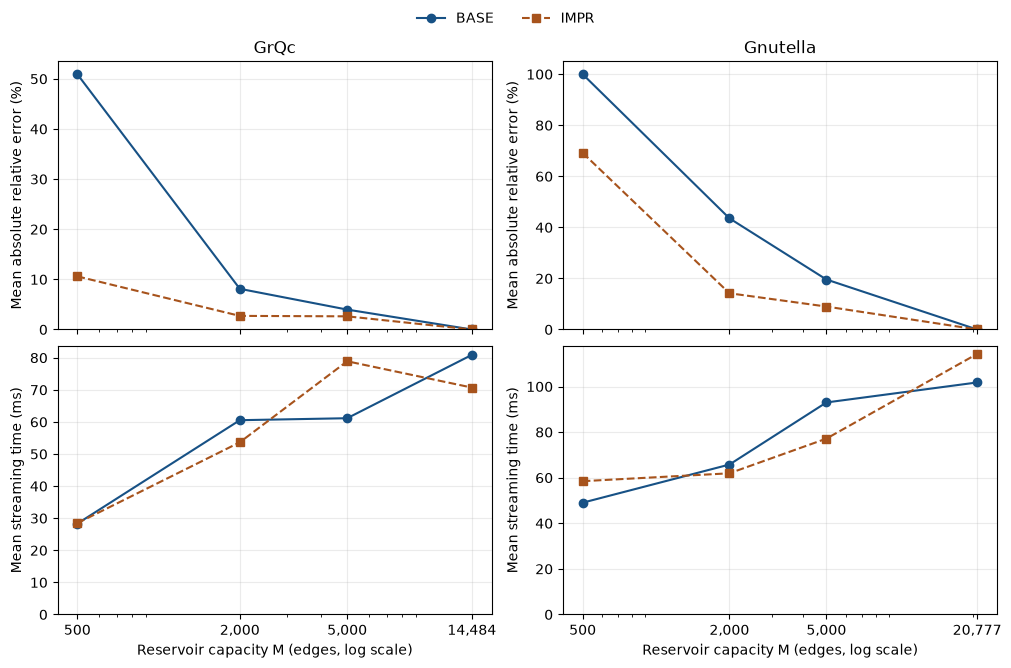

In [8]:
styles = {
    "base": {"marker": "o", "linestyle": "-", "color": "#175185", "label": "BASE"},
    "impr": {"marker": "s", "linestyle": "--", "color": "#a7531c", "label": "IMPR"},
}
# 同一列上下使用同样的容量刻度，方便对照误差与耗时。
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6), sharex="col", layout="constrained")

for col, (filename, name) in enumerate(names.items()):
    accuracy_ax, runtime_ax = axes[:, col]
    for variant, style in styles.items():
        group = [
            row for row in summary
            if row["dataset"] == filename and row["variant"] == variant
        ]
        capacities = [row["capacity"] for row in group]
        accuracy_ax.plot(
            capacities, [100 * row["mean_relative_error"] for row in group], **style,
        )
        runtime_ax.plot(
            capacities, [1000 * row["mean_seconds"] for row in group], **style,
        )

    accuracy_ax.set_title(name)
    accuracy_ax.set_ylabel("Mean absolute relative error (%)")
    runtime_ax.set_ylabel("Mean streaming time (ms)")
    runtime_ax.set_xlabel("Reservoir capacity M (edges, log scale)")
    # 对数横轴保留小容量间距，最右点仍使用实际全量边数。
    runtime_ax.set_xscale("log")
    runtime_ax.set_xticks(capacities, [f"{capacity:,}" for capacity in capacities])

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.set_ylim(bottom=0)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2, frameon=False)
fig.savefig(OUT / "accuracy_runtime.png", dpi=140)
plt.show()

**上排为什么从左到右下降？** 在本次实验里，样本越大越容易保住三角形的多条边。最明显的是 Gnutella 的 BASE 在容量 500 时，十个样本均没有完整三角形，估计为 0、误差 100%，且估计标准差也是 0。零标准差只表示这十次结果相同。IMPR 可在新边到达时检查它，即使新边随后被跳过，因而同一预算下有不同的计数机会。上排的曲线是这些组合的平均误差，不能保证每个种子的误差随容量单调下降。

**下排怎样比较？** 同一列内在同个横轴值比较两条线，读出该容量下的平均流耗时。大样本可能带来更大的邻接表；BASE 主要在接收时更新计数，IMPR 对每条到达边做检查。这些开销会受到图结构和实际采样的影响。本机短时间运行也会受系统负载影响，细小的时间差不能当成稳定的速度排名。

<a id="trace"></a>

## 6. 同一条边流上，估计如何变化

上一节横轴是样本容量，只比较流结束时的结果。这一节固定 GrQc、容量 2,000、采样种子 0，横轴改为已处理的边数。这样可以指出在什么时候开始抽样，以及一条具体运行轨迹是否持续高估或低估。

**下面重放同一条边流。** 用 `read_graph` 和种子 42 重建 §5 的边序，把每条边交给两个 `Triest.update`。每 1,000 条边以及流结束时，通过 `exact_triangles` 单独对边前缀数准确值。例如横轴 3,000 处比较的是前三千条边组成的图。最后一点是全长 14,484 条边。前缀的完整边只用于离线对照，其开销未计入上一节的流耗时。

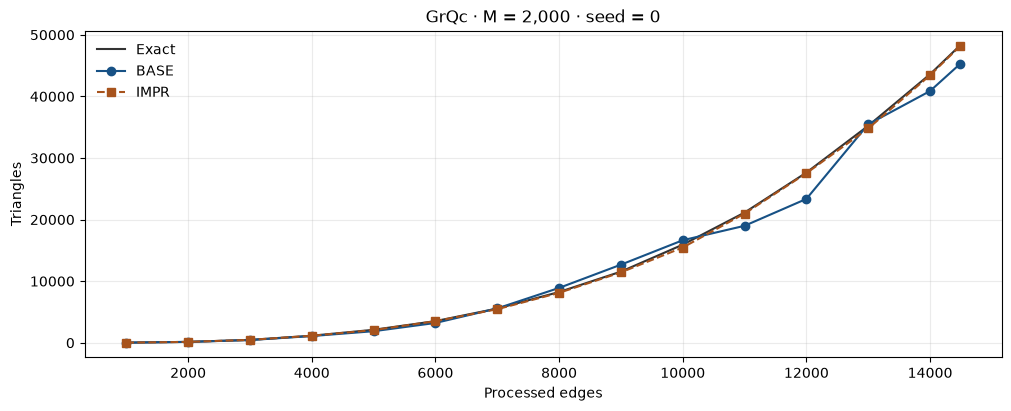

In [9]:
edges, _ = read_graph(DEFAULT_PATHS[0])
# 和主实验使用同一顺序，末点可与种子 0 的运行明细对照。
random.Random(DEFAULT_ORDER_SEED).shuffle(edges)
estimators = {variant: Triest(2000, seed=0, variant=variant) for variant in styles}
trace = []

# enumerate(..., 1) 让第一个边的处理编号从 1 开始。
for processed, edge in enumerate(edges, 1):
    for estimator in estimators.values():
        estimator.update(*edge)

    # 真值每千条边离线算一次，比每条边都重新枚举易于复现。
    if processed % 1000 == 0 or processed == len(edges):
        # edges[:processed] 切出当前前缀，这里只需要准确总数。
        exact, _ = exact_triangles(edges[:processed])
        trace.append({
            "t": processed,
            "exact": exact,
            **{variant: estimator.estimate() for variant, estimator in estimators.items()},
        })

# 保存绘图所用的点，可按处理边数复核三条曲线。
with (OUT / "stream_trace.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(trace[0]))
    writer.writeheader()
    writer.writerows(trace)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
processed_edges = [row["t"] for row in trace]
ax.plot(processed_edges, [row["exact"] for row in trace], color="#333333", label="Exact")
for variant, style in styles.items():
    ax.plot(processed_edges, [row[variant] for row in trace], **style)

ax.set(title="GrQc · M = 2,000 · seed = 0", xlabel="Processed edges", ylabel="Triangles")
ax.grid(alpha=0.25)
ax.legend(loc="upper left", frameon=False)
fig.savefig(OUT / "stream_trace.png", dpi=140)
plt.show()

**逐点看前缀。** 前 1,000、2,000 条边的三个值分别重合在 20 和 142，因为此时样本仍容纳全部边。3,000 条边时，准确值为 467，BASE 约 442.3，IMPR 约 470.8；超出容量后，两个估计开始由样本是否保留相关边决定。流结束时，这一次 BASE 约 45,256.8、IMPR 约 48,150.4，准确值是 48,260。BASE 在 9,000 条边附近高估、到结尾低估。这条轨迹说明单次误差可以换方向，同一算法跨种子的表现仍要看 §5 的汇总。

<a id="conclusion"></a>

## 7. 结论与来源

### 自己动手检查两个边界

- 试着预测完全图例子里的最后一行。四个点中任选三个，恰好可以选出四组，所以 `K4` 有 4 个三角形。每个点和其他三个点中的任意两个组成一个三角形，因此每个点参与 3 个。
- 打开学习目录下的 `results/TW3/runs.csv`。筛出 `dataset=ca-GrQc.txt.gz`、`variant=base`、`capacity=5000`、`seed=0` 的一行。用这一行的 `estimate` 和 `exact` 算 $|\mathrm{estimate}-\mathrm{exact}|/\mathrm{exact}$，再乘 100 得到约 8.09%。去掉种子筛选后可看到十行，对这十个百分数取平均就得到约 3.97%。

### 现场怎么讲

先用自己的话练习一遍。打开英文报告时，可以按小图、真实数据、限制这个顺序演示。问到运行时间，指向自己重跑后表里的毫秒数，讲清哪一列只算流更新。

> We estimate how many triangles have appeared in a stream of graph edges. The reservoir can hold at most M edges. BASE counts complete triangles in the sample and scales that count by their inclusion probability. IMPR checks each new edge against the old sample before deciding whether to keep it. On GrQc, BASE's mean absolute relative error was about 3.97 percent at a capacity of 5,000 edges. When the reservoir held every edge, both variants matched the exact counts.

| 助教可能问什么 | 怎样抓住重点 |
| --- | --- |
| Why is the estimate sometimes zero? | BASE 需要三条边同时入样。Gnutella 在容量 500 的这十次 BASE 实验里没看到完整三角形，所以十次估计都是零。全图仍有 2,383 个三角形。 |
| What does unbiased mean here? | 固定图和边顺序，反复抽样时估计的期望等于真值。一次抽样可能高估，也可能低估。 |
| Can the stream continue indefinitely? | 全局估计器可以一直处理符合条件的插入，空间由容量限制。精度还要看图和容量。实验的读入、去重、打乱和准确计数会保存整张图。 |
| Can you split it across workers or delete edges? | 对这份实现，每次更新用到上一步的样本。随手分流再把各自估计相加会遗漏跨分区闭合的三角形。当前版本只处理插入。论文的 TRIÈST-FD 用不同的抽样维护规则支持删除。 |

这份实现先用蓄水池均匀挑边，再用 BASE 把样本中看得见的三角形换算成全图估计。40 次全量容量运行都与独立真值相符。抽样条件下，GrQc 的 BASE 在容量从 500 增到 5,000 时，平均绝对相对误差由约 50.93% 降到 3.97%。Gnutella 同样容量 5,000 时仍有 19.58% 的误差。两张图说明相同边数预算可以带来不同精度。这里比较的是固定顺序、每组 10 个种子的结果，重复性和数学推导分别由实验与第 2 至 3 节给出。

核心全局估计器的空间受样本容量 $M$ 约束。清洗、打乱、独立真值和前缀基准属于需要全图的离线环节。实测耗时适用于本机的 Python 环境、两份数据和这些容量。

BASE 和 IMPR 对应论文 §4.1 和 §4.2。[De Stefani 等，KDD 2016](https://www.kdd.org/kdd2016/papers/files/rfp0465-de-stefaniA.pdf) · [Canvas Homework 3](https://canvas.kth.se/courses/65339/assignments/402870)

### AI 使用说明

**AI 使用工具** OpenAI Codex

Codex 协助理解作业要求、审阅算法结构、改写代码注释和 Notebook 讲解，也协助整理演示材料。笔记中的实验在本机使用原始数据运行。学生负责核对实现、结果与提交文件。